# Physics Baseline

In [1]:
import os
import glob
import numpy as np
np.random.seed(123456789)
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

import re
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Automatically detect if running on Kaggle or Locally
IS_KAGGLE = os.path.exists('/kaggle/input')
BASE_DIR = '/kaggle/input/competitions/rogii-wellbore-geology-prediction' if IS_KAGGLE else '../data'

print(f"Running on {'Kaggle' if IS_KAGGLE else 'Local Environment'}")
print(f"Data Directory: {BASE_DIR}")
train_data = os.path.join(BASE_DIR, "train")
file_paths = sorted(os.listdir(train_data))
file_paths[:10]

Running on Local Environment
Data Directory: ../data


['000d7d20.png',
 '000d7d20__horizontal_well.csv',
 '000d7d20__typewell.csv',
 '00bbac68.png',
 '00bbac68__horizontal_well.csv',
 '00bbac68__typewell.csv',
 '00e12e8b.png',
 '00e12e8b__horizontal_well.csv',
 '00e12e8b__typewell.csv',
 '015fe0d2.png']

In [3]:
# Regex pattern: 
pattern = re.compile(r'([^/\\]+)__horizontal_well\.csv')

well_names = []
for path in file_paths:
    match = pattern.search(path)
    if match:
        well_names.append(match.group(1))

print("Extracted Well Names:")
print(len(well_names), "Well Names")

Extracted Well Names:
773 Well Names


In [4]:
from scipy.signal import butter, filtfilt
def remove_rotation_noise(gr_series, cutoff):
    """
    Low pass filter.
    """
    # 1. Handle NaNs safely
    gr_filled = gr_series.interpolate(method='linear').bfill().ffill()
    
    # 2. Design the Butterworth Filter
    # Nyquist frequency is 0.5 (half of our 1-foot sample rate)
    nyquist = 0.5 
    normal_cutoff = cutoff / nyquist
    
    # Order 4 is strong enough to kill the noise without distorting the geology
    b, a = butter(1, normal_cutoff, btype='low', analog=False)
    
    # 3. Apply Zero-Phase Filtering
    gr_clean = filtfilt(b, a, gr_filled)
    
    # Put the NaNs back exactly where they were originally (if you need them)
    # gr_clean[gr_series.isna()] = np.nan 
    
    return gr_clean

from scipy.signal import find_peaks as p
def find_peaks(x_, y_, prominence, distance):

    # x = x_.copy().reset_index(drop=True)
    # y = y_.copy().reset_index(drop=True)
    
    # 2. Find the Prominent Peaks
    # The 'prominence' value requires tuning based on your specific data's scale.
    # 'distance' ensures you don't get two peaks right next to each other.
    peaks, properties = p(y, prominence=prominence, distance=distance)
    
    # 3. Calculate the boundaries (midpoints between major peaks)
    # We add the very beginning (0) and very end (length of array) to the boundaries
    midpoints = (peaks[:-1] + peaks[1:]) // 2
    boundaries = [0] + midpoints.tolist() + [len(y)]

    return peaks, properties, midpoints, boundaries
    

In [5]:
well = np.random.choice(well_names)

# Good Scoring:
'729f4217'
'ff0aea78'
# Bad Scoring:
'493b5b31: 180 API centre peak breaking everything'
'8f201368: Multiple Breaks without Peaks in the beginning'
'c99f9fae: Bad Ending' 
'2e63d9de: Unable to capture the rising TVT, one crest behind'
'511e1db0: One crest fails to match, rest gets matched'
'7d50373e: Fails to match, bad score'
'9c350a6a: Bad Score'
'7224331b: Bad Score: It seems to use the wrong curve after 17100'
'ccedb12b: 15 feet vertical TVT jump'
'SVG Failed to Converge'
'fef8af96: Bad Score'
'6d6d93af: Centre peaks dont get picked'

# Weird Values
'91b301ce: High TVT Range', 
'5f4d2a52: VERY bad score, doesnt have GR peaks in the beginning, has plain start with 150 API peaks at the end'
'ba48188d, 91b301ce, 5f4d2a52: High STD for TVT: 30-35, next is 26'

'a3518960, 5a5269a9, 7271dd80 : Shows discontinuity/jumps can exist in tvt'
'000d7d20 Doesnt match the GR vs MD plot'
'fb0904bd: Why is its GR so much choppy'
'276b012a: Singe first peak takes all the varience'

'aaeffccb: Last 5 feet peak algo failing'

# Geologist's Mistakes:
'1b1eba53'
'86454a6f'
'



well, hw.shape, tw.shape

NameError: name 'hw' is not defined

## Hypothesis:
* Star steer calculates $TVT - TVT_0 = |Z| - |Z_0| - (m * MD + c)$ for every chunk
    * Absolute Space &rarr; Stratigraphic Space
    * Where $m and c$ are optimized to have the best $GR$ wave match using this chunk and the other chunks
    * The $TVT_0$ for the other chunk is choosen to be the last predicted $TVT$ in the chunk

## Flow:
* Find how division in chunks could be replicated close to the geologist's division.
    * Making chunks on the basis of points of inflection/maximas/minimas/their midpoints.
* You have $TVT_{start}$ with $Z_{start}$ and $Z_{end}$ for a chunk.
* You want $TVT_{b/w}$
    * Such that the points with $start$ and $end$ form a straight line in TVT + Z vs MD.
    * Match GR
        * ME: Such that the interp from tw is maximized in correlation with GR in the chunk. Matching GR vs MD
        * Geologist: Mathing bit by bit the GR of hw to tw's. Matching GR vs TVT
* Match GR vs np.interp(TVT) from Zi to Zi + 1, hence get TVTi + 1
* $ TVT = m * (Z - Z_i) + TVT_i $

* Using beam search

# Physics Baseline: Strat Based Persepective

$TVT_{current} = TVT_{anchor} - (Z_{current} - Z_{anchor}) - m \times (HD_{cum\_current} - HD_{cum\_anchor})$

In [210]:
HW_LOW_PASS_CUTOFF = 0.009
PEAK_PROMINENCE = 3.0
PEAK_DISTANCE = 50
EXTRA_DIVISIONS = [20, 70, 150]

fill = lambda df: df.interpolate(method='linear', limit_direction='both')
d = lambda df: fill(df).diff().rolling(11, center=True, min_periods=1).mean()

Executing Vectorized 2D Grid Beam Search with Hybrid Metric...
Overall RMSE between Final Concatenated TVT and evalz['TVT']: 53.362528


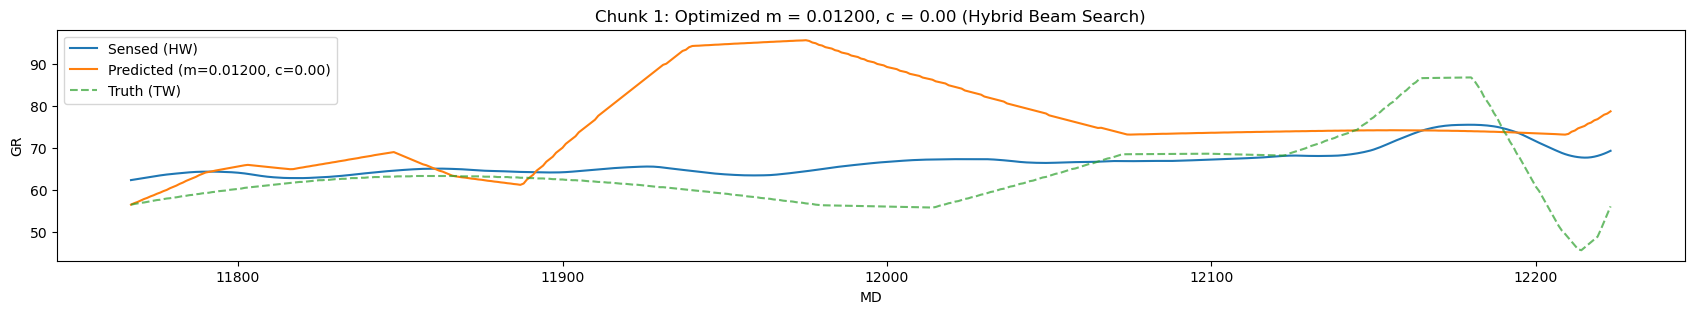

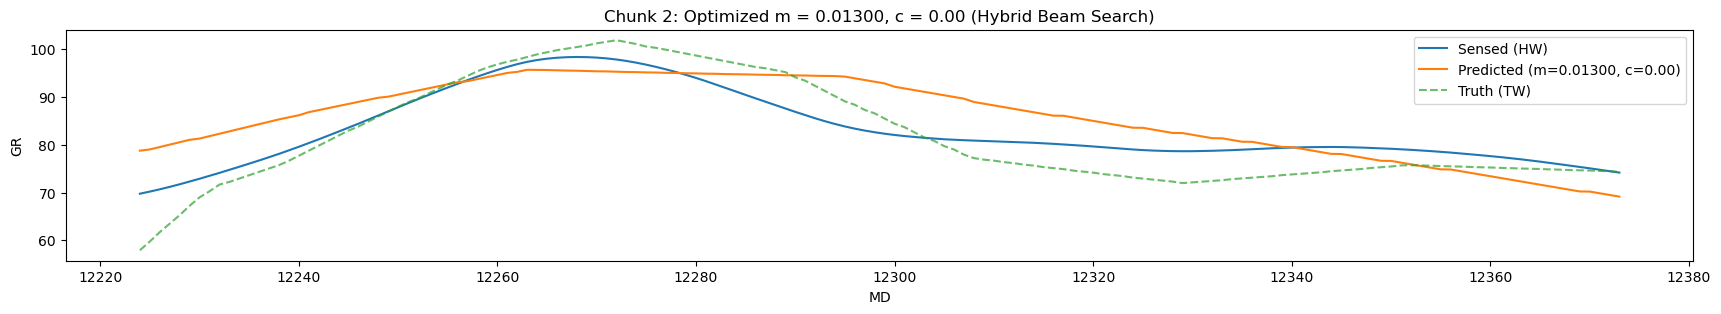

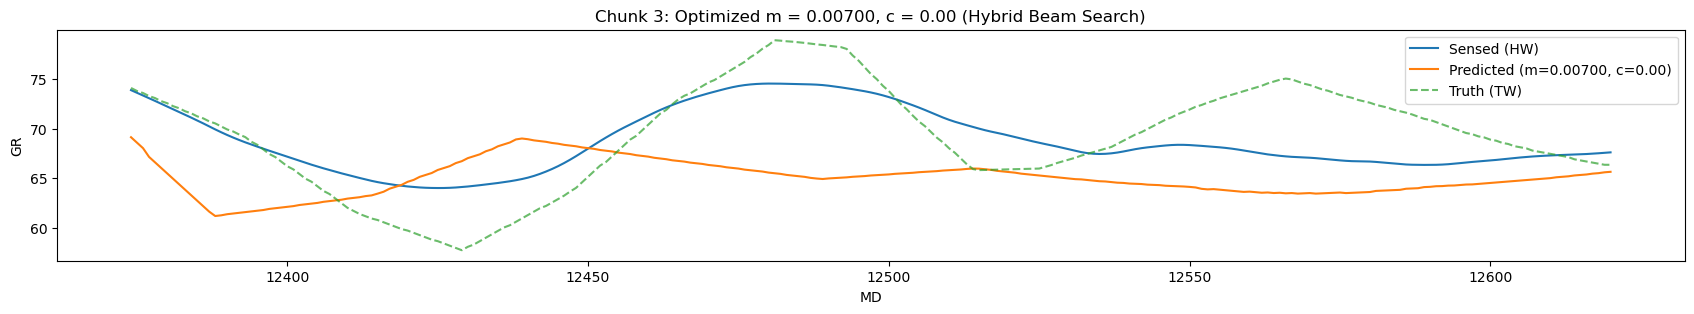

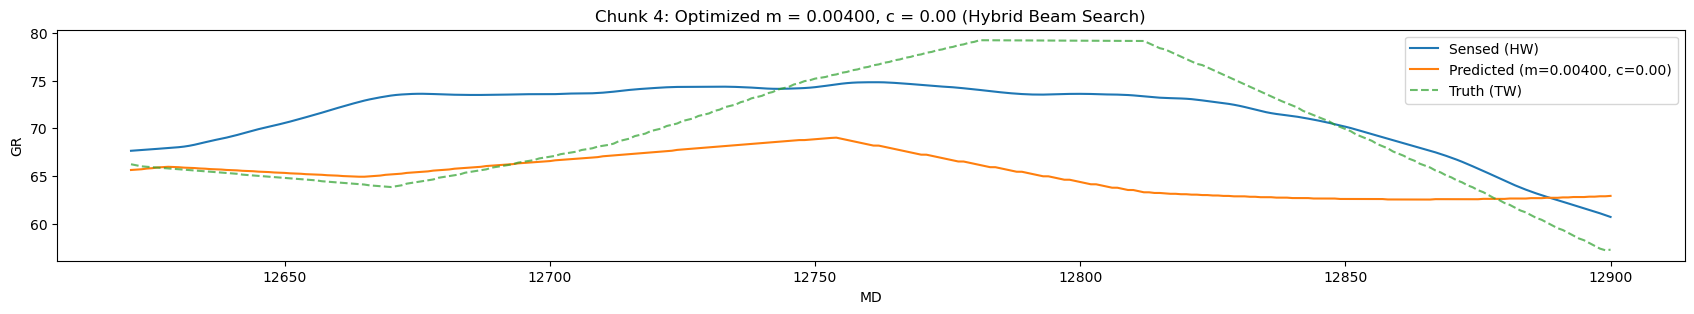

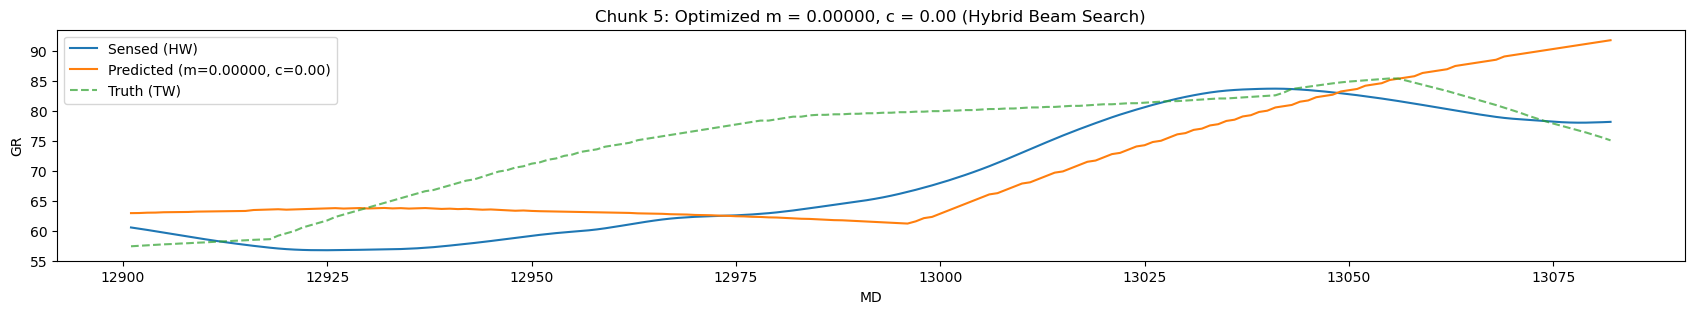

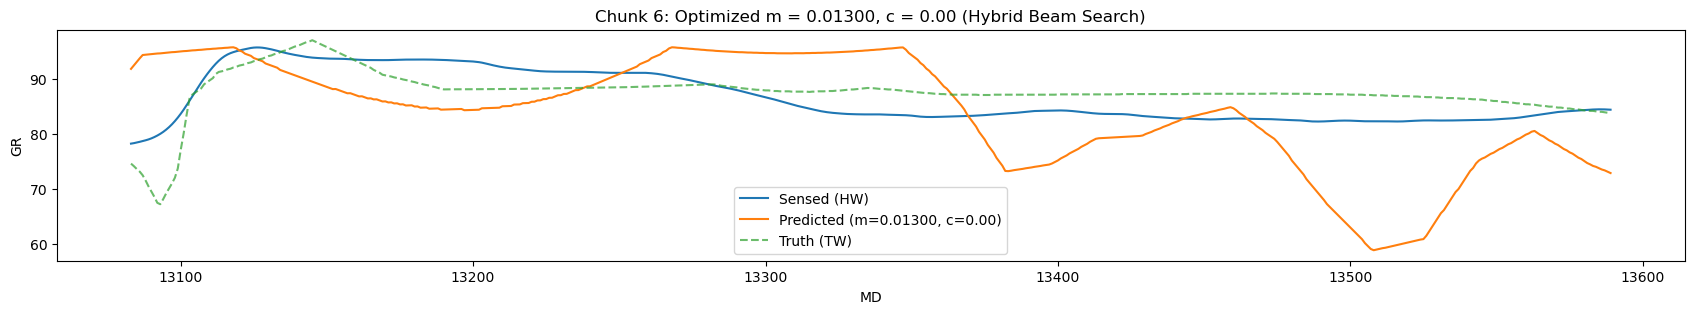

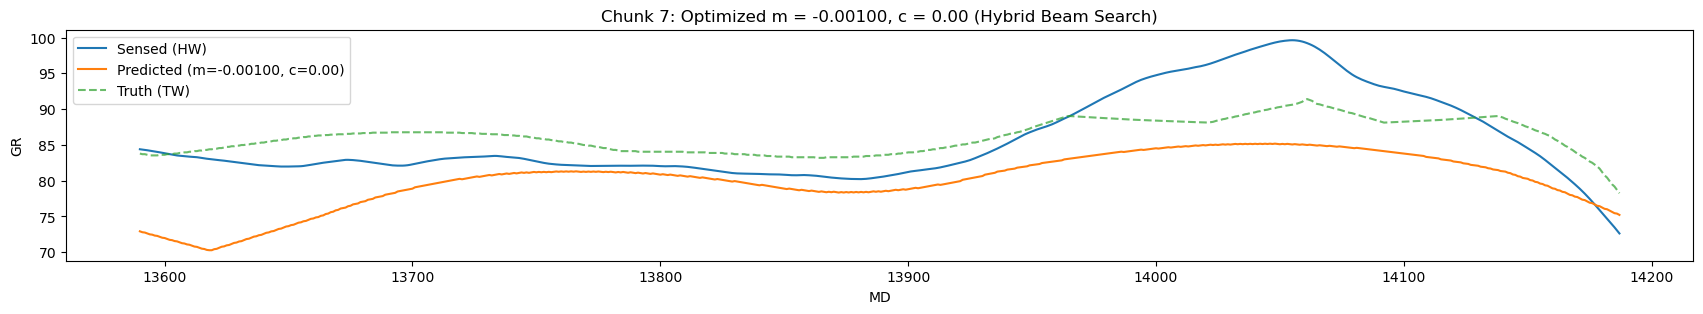

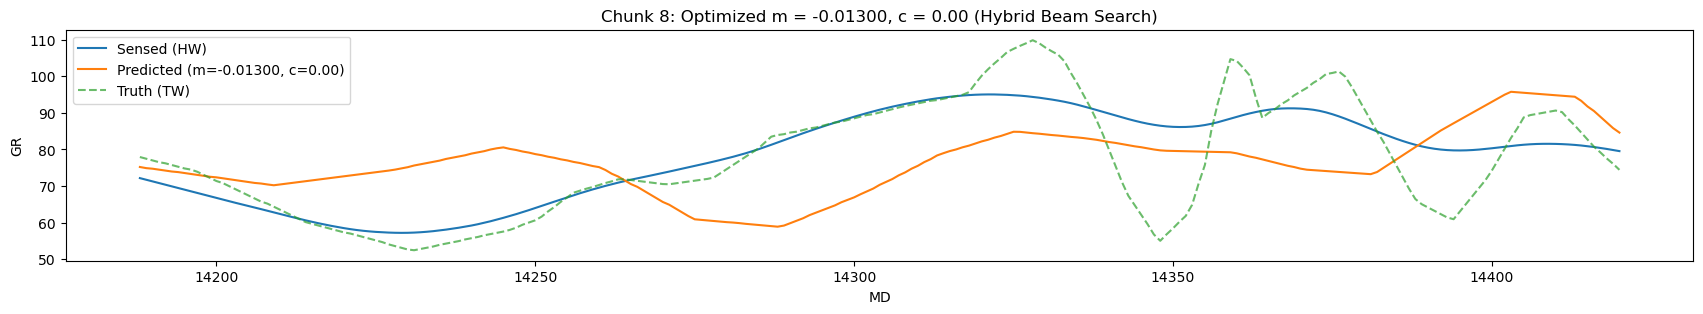

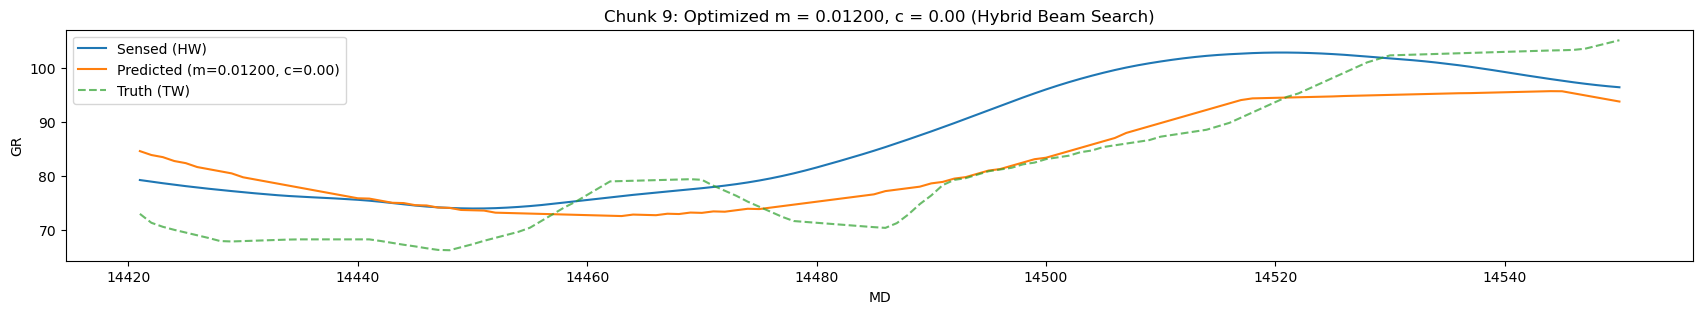

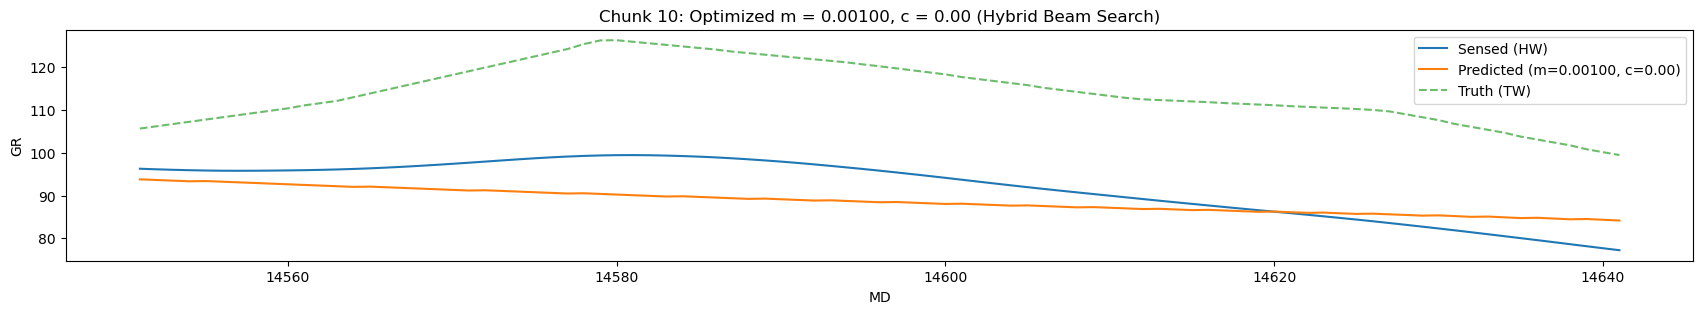

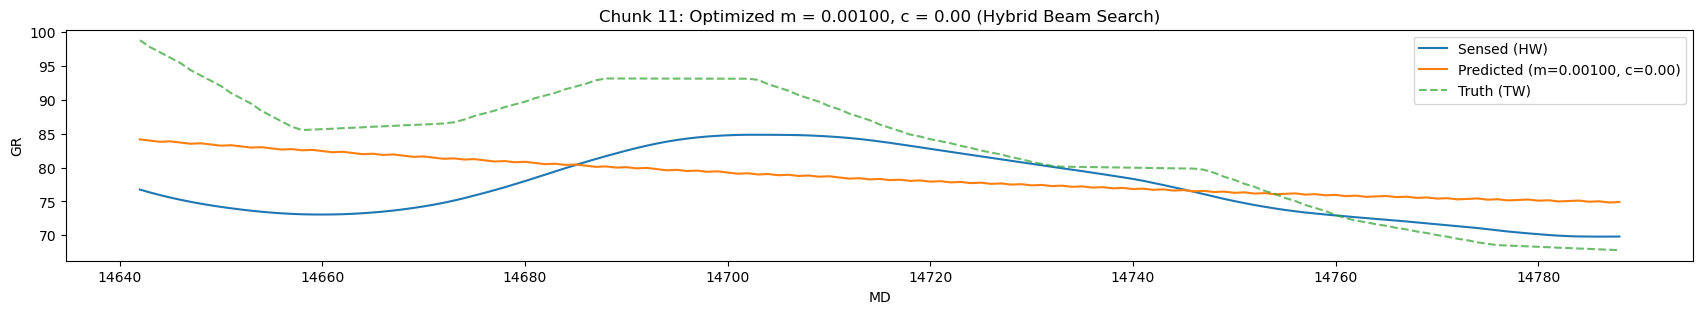

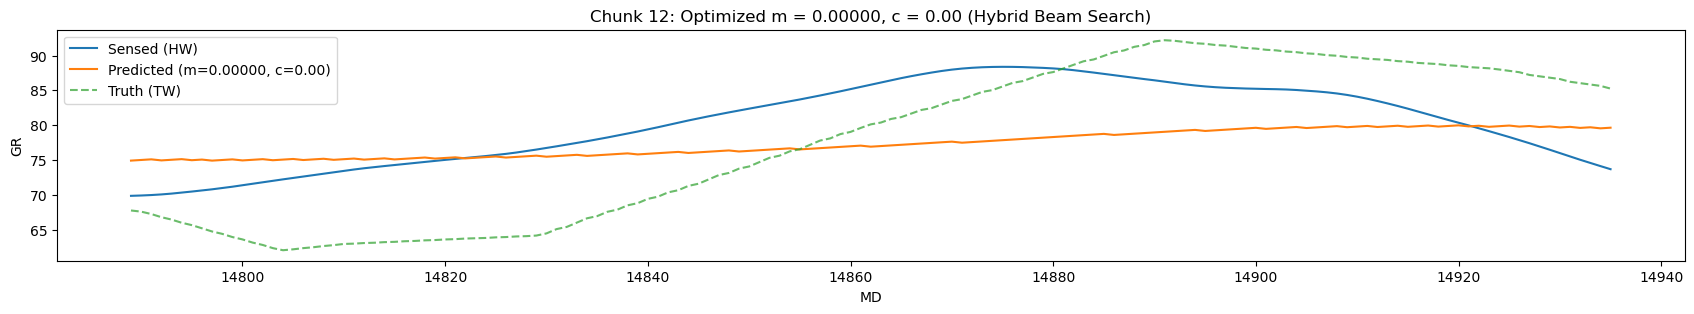

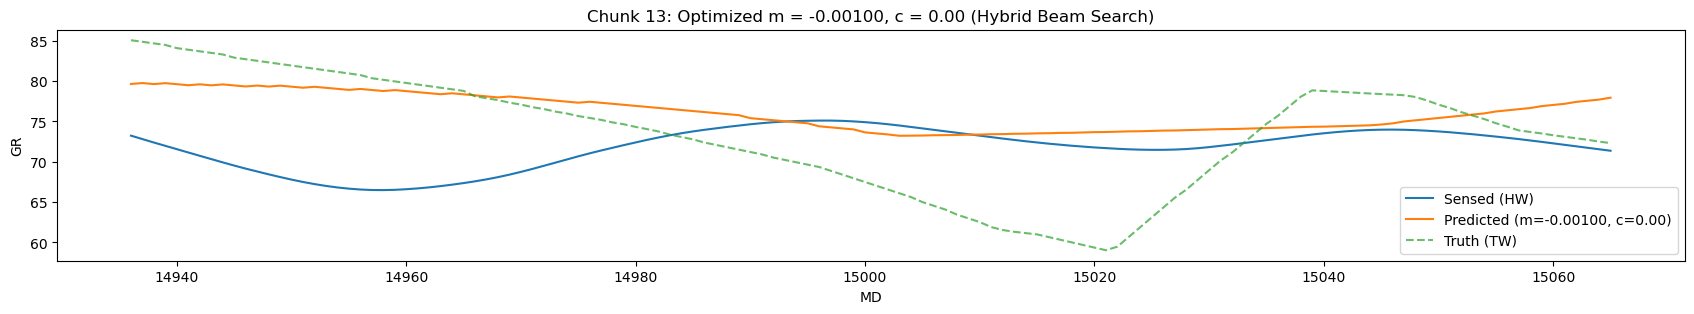

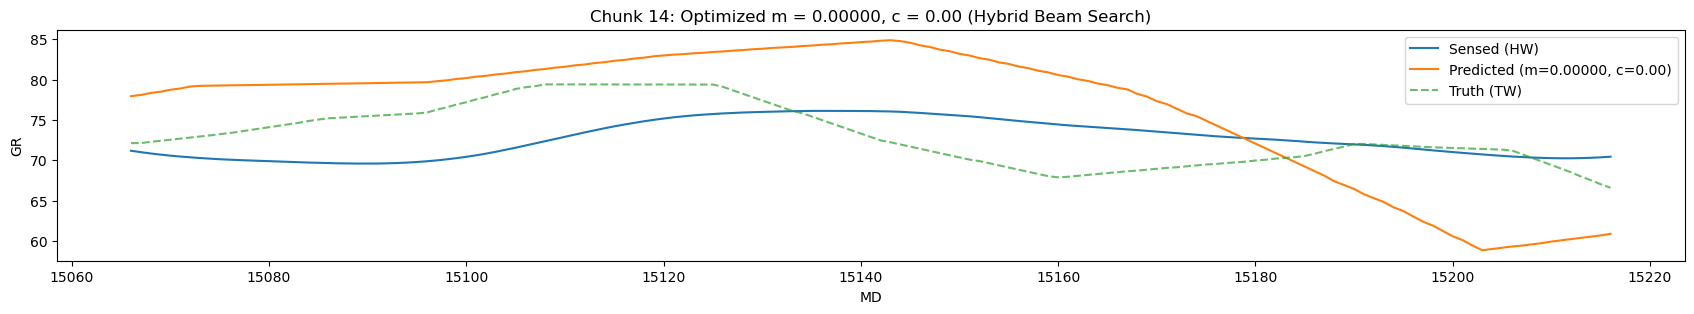

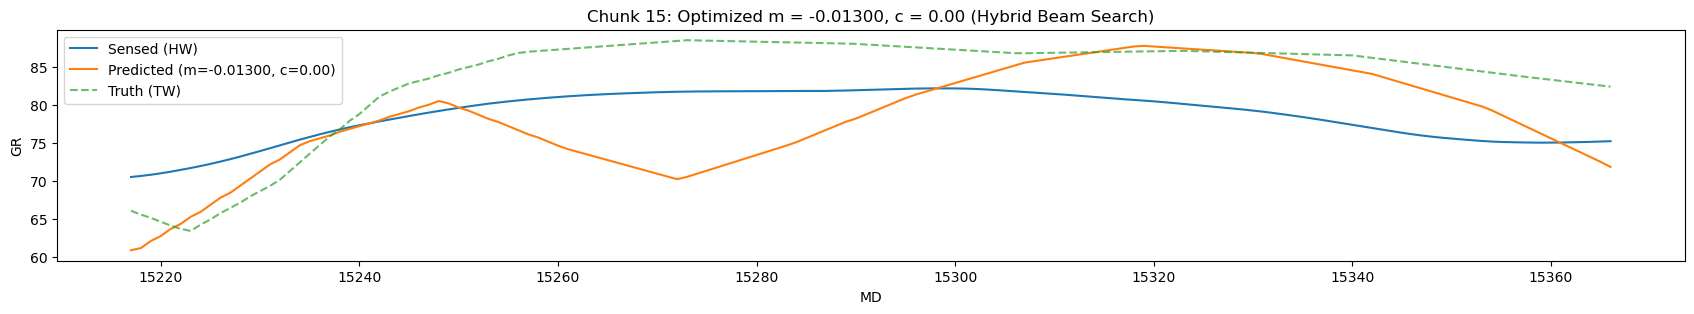

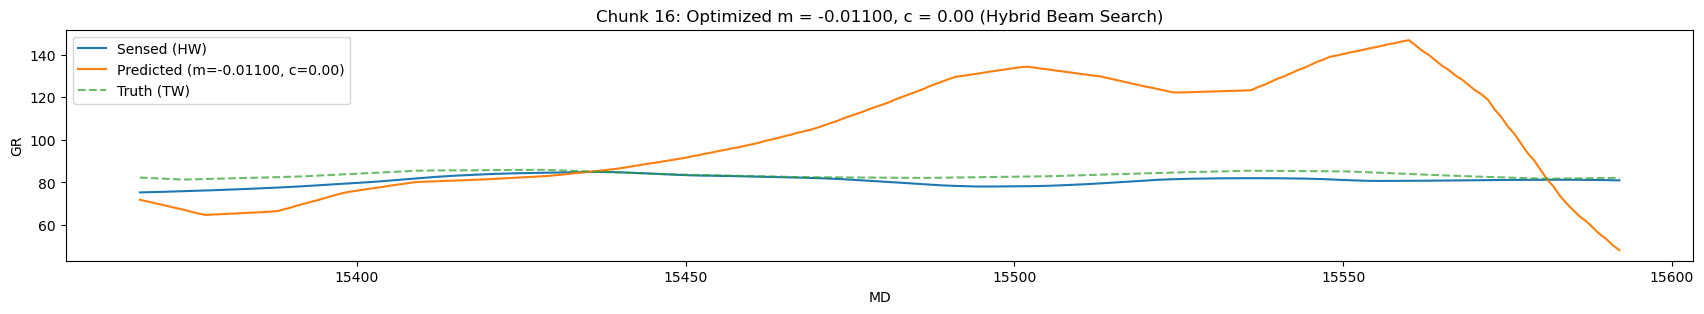

In [259]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, butter, filtfilt
import warnings
warnings.filterwarnings('ignore')

# --- 1. DATA PREPARATION ---
IS_KAGGLE = os.path.exists('/kaggle/input')
BASE_DIR = '/kaggle/input/competitions/rogii-wellbore-geology-prediction' if IS_KAGGLE else '../data'
train_data = os.path.join(BASE_DIR, "train")

def remove_rotation_noise(gr_series, cutoff):
    gr_filled = gr_series.interpolate(method='linear').bfill().ffill()
    nyquist = 0.5 
    normal_cutoff = cutoff / nyquist
    b, a = butter(1, normal_cutoff, btype='low', analog=False)
    return filtfilt(b, a, gr_filled)

hw = pd.read_csv(os.path.join(train_data, f"{well}__horizontal_well.csv"))
tw = pd.read_csv(os.path.join(train_data, f"{well}__typewell.csv"))

mask = hw['TVT_input'].isna()
evalz = hw[mask].copy()

### ------------

mask = hw['TVT_input'].isna()
norm_hw = hw[~mask].iloc[-1000:].copy()
hw_gr_calib = remove_rotation_noise(norm_hw['GR'], HW_LOW_PASS_CUTOFF)
hw_tvt_calib = norm_hw['TVT_input']
tw_gr_calib = np.interp(hw_tvt_calib, tw['TVT'], tw['GR'])

# Calculate the mean and standard deviation for the overlapping section
hw_mean, hw_std = np.mean(hw_gr_calib), np.std(hw_gr_calib)
tw_mean, tw_std = np.mean(tw_gr_calib), np.std(tw_gr_calib)

evalz = hw[mask].copy()
evalz['GR_raw'] = (evalz['GR'].copy() - hw_mean) / hw_std * tw_std + tw_mean

fill = lambda df: df.interpolate(method='linear', limit_direction='both')
d = lambda df: fill(df).diff().rolling(11, center=True, min_periods=1).mean()

# Normalizing Z and computing pure TVD
slope, intercept = np.polyfit(evalz['MD'], evalz['Z'], deg=1)
pred = evalz['Z'] - evalz['MD'] * slope - intercept
evalz['norm_Z'] = pred - pred.iloc[0] 

# Keep a raw copy of GR to allow dynamic filtering via slider
evalz['GR_raw'] = evalz['GR'].copy()
evalz['GR'] = remove_rotation_noise(evalz['GR_raw'], cutoff=HW_LOW_PASS_CUTOFF)

### -----------

# Normalize GR

# evalz_std, evalz_mean = evalz['GR'].std(), evalz['GR'].mean()
# evalz['GR'] -= evalz_mean
# evalz['GR'] /= evalz_std
# tvt0 = hw[~mask]['TVT'].iloc[0]
# tw_mask = tw['TVT'].between(tvt0 - 60, tvt0 + 60, inclusive='neither')
# tw_std, tw_mean = tw['GR'][tw_mask].std(), tw['GR'][tw_mask].mean()
# tw['GR'] -= tw_mean
# tw['GR'] /= tw_std

slope, intercept = np.polyfit(evalz['MD'], evalz['Z'], deg=1)
pred = evalz['Z'] - evalz['MD'] * slope - intercept
pred_norm = pred - pred.iloc[0] 
tvt_norm = -evalz['TVT'] + evalz['TVT'].iloc[0]

evalz['norm_TVT'] = tvt_norm
evalz['norm_Z'] = pred_norm
evalz['Z-bl'] = evalz['norm_TVT'] - evalz['norm_Z']
# evalz['GR'] = remove_rotation_noise(evalz['GR'], cutoff=0.009)

# Chunk Generation via Prominent Peaks
x = evalz['MD'].copy().reset_index(drop=True)
y = evalz['GR'].copy().reset_index(drop=True)
peaks, _ = find_peaks(y, prominence=3.0, distance=50)
midpoints = (peaks[:-1] + peaks[1:]) // 2
boundaries = [0] + midpoints.tolist() + [len(y)]

chunks = [evalz.iloc[boundaries[i]:boundaries[i+1]] for i in range(len(boundaries)-1)]

# --- 2. VECTORIZED BEAM SEARCH (HYBRID CORRELATION + RMSE) ---
ms = np.arange(0.013, -0.014, -0.001) # Start, End, Step-size
# cs = np.arange(9, -10, -1)
# cs = np.array([-7, 3, 0, -3, 7])
cs = np.array([0])
# Create a flattened grid of every (m, c) combination
M_grid, C_grid = np.meshgrid(ms, cs, indexing='ij')
M_flat = M_grid.ravel()
C_flat = C_grid.ravel()

initial_tvt_0 = evalz['TVT'].iloc[0]
beam_width = 300 

tw_tvt_vals = tw['TVT'].values
tw_gr_vals = tw['GR'].values

beams = [{
    "tvt_0": initial_tvt_0,
    "m_path": [],
    "c_path": [],
    "total_error": 0.0,
    "tvt_cands": [],
    "gr_cands": []
}]

print("Executing Vectorized 2D Grid Beam Search with Hybrid Metric...")

for i, chunk in enumerate(chunks):
    md_arr = chunk['MD'].values
    gr_arr = chunk['GR'].values
    md_0 = md_arr[0]
    
    # Pre-calculate the Z-shift and MD-differences for the whole chunk
    norm_z_shift = chunk['norm_Z'].values - chunk['norm_Z'].iloc[0]
    md_diff = md_arr - md_0
    
    new_beams = []
    
    for beam in beams:
        # 1. VECTORIZED TVT CALCULATION (Combines M_flat and C_flat)
        tvt_matrix = M_flat[:, None] * md_diff - norm_z_shift + beam["tvt_0"] + C_flat[:, None]
        
        # 2. VECTORIZED INTERPOLATION
        gr_pred_matrix = np.interp(
            tvt_matrix.ravel(), 
            tw_tvt_vals, 
            tw_gr_vals, 
            left=np.nan, 
            right=np.nan
        ).reshape(tvt_matrix.shape)
        
        # 3. FAST HYBRID CALCULATION FOR EACH CANDIDATE
        # Calculate MSE to ground the vertical distance
        sq_errors = (gr_pred_matrix - gr_arr)**2
        mses = np.nanmean(sq_errors, axis=1)
        
        chunk_costs = np.zeros(gr_pred_matrix.shape[0])
        for j in range(gr_pred_matrix.shape[0]):
            valid_mask = ~np.isnan(gr_pred_matrix[j]) & ~np.isnan(gr_arr)
            if np.sum(valid_mask) > 5:
                x_vals = gr_pred_matrix[j, valid_mask]
                y_vals = gr_arr[valid_mask]
                
                if (np.std(x_vals) > 1e-5 and np.std(y_vals) > 1e-5) and False:
                    c_val = np.corrcoef(x_vals, y_vals)[0, 1]
                    
                    # THE HYBRID COST
                    # Combines the Shape-Matching of Correlation with the Vertical-Grounding of MSE
                    chunk_costs[j] = ((1.0 - c_val) * 1000) #+ mses[j]
                else:
                    # If the segment is completely flat, rely on MSE only
                    chunk_costs[j] = mses[j] if not np.isnan(mses[j]) else 1e6
            else:
                chunk_costs[j] = 1e6
        
        # 4. BRANCH CREATION
        for j in range(len(M_flat)):
            new_beams.append({
                "tvt_0": tvt_matrix[j, -1],
                "m_path": beam["m_path"] + [M_flat[j]],
                "c_path": beam["c_path"] + [C_flat[j]],
                "total_error": beam["total_error"] + chunk_costs[j],
                "tvt_cands": beam["tvt_cands"] + [pd.Series(tvt_matrix[j], index=chunk.index)],
                "gr_cands": beam["gr_cands"] + [pd.Series(gr_pred_matrix[j], index=chunk.index)]
            })
            
    # Sort and prune beams to strictly enforce beam width
    new_beams.sort(key=lambda x: x["total_error"])
    beams = new_beams[:beam_width]

# --- 3. EXTRACT RESULTS AND PLOT ---
best_overall_path = beams[0]
best_m_sequence = best_overall_path["m_path"]
best_c_sequence = best_overall_path["c_path"]
best_gr_sequence = best_overall_path["gr_cands"]
best_tvt_sequence = best_overall_path["tvt_cands"]

# Calculate Overall RMSE against the evalz ground truth
final_tvt = pd.concat(best_tvt_sequence)
final_rmse = np.sqrt(np.nanmean((final_tvt - evalz['TVT'])**2))
print(f"Overall RMSE between Final Concatenated TVT and evalz['TVT']: {final_rmse:.6f}")

# Plot the individual chunks
for i, chunk in enumerate(chunks):
    plt.figure(figsize=(21, 3))
    
    best_m = best_m_sequence[i]
    best_c = best_c_sequence[i]
    best_pred_gr = best_gr_sequence[i]
    
    plt.plot(chunk['MD'], chunk['GR'], label='Sensed (HW)')
    plt.plot(chunk['MD'], best_pred_gr, label=f"Predicted (m={best_m:.5f}, c={best_c:.2f})")
    
    truth_gr = np.interp(chunk['TVT'], tw['TVT'], tw['GR']) 
    plt.plot(chunk['MD'], truth_gr, label="Truth (TW)", linestyle='--', alpha=0.7)
    
    plt.title(f"Chunk {i+1}: Optimized m = {best_m:.5f}, c = {best_c:.2f} (Hybrid Beam Search)")
    plt.xlabel("MD")
    plt.ylabel("GR")
    plt.legend()

plt.show()

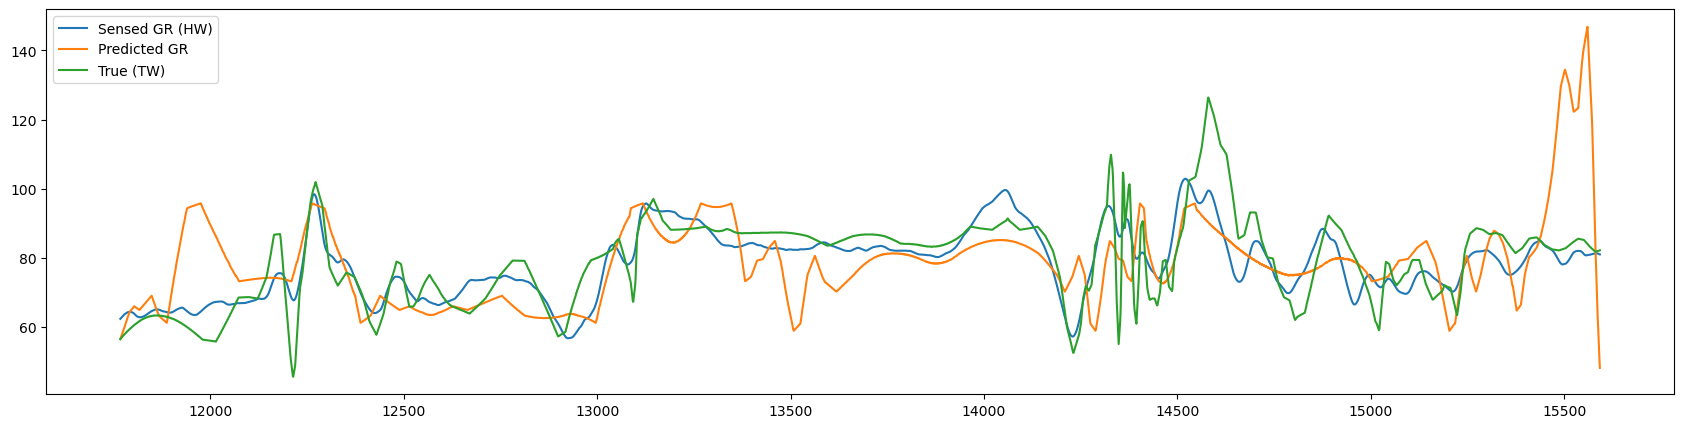

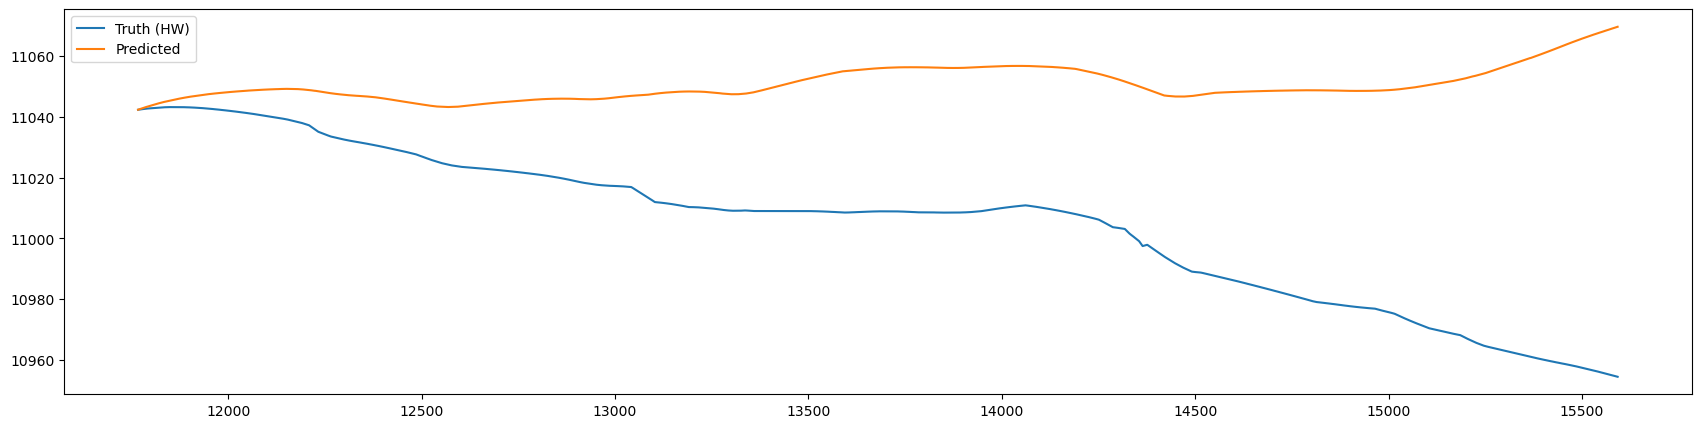

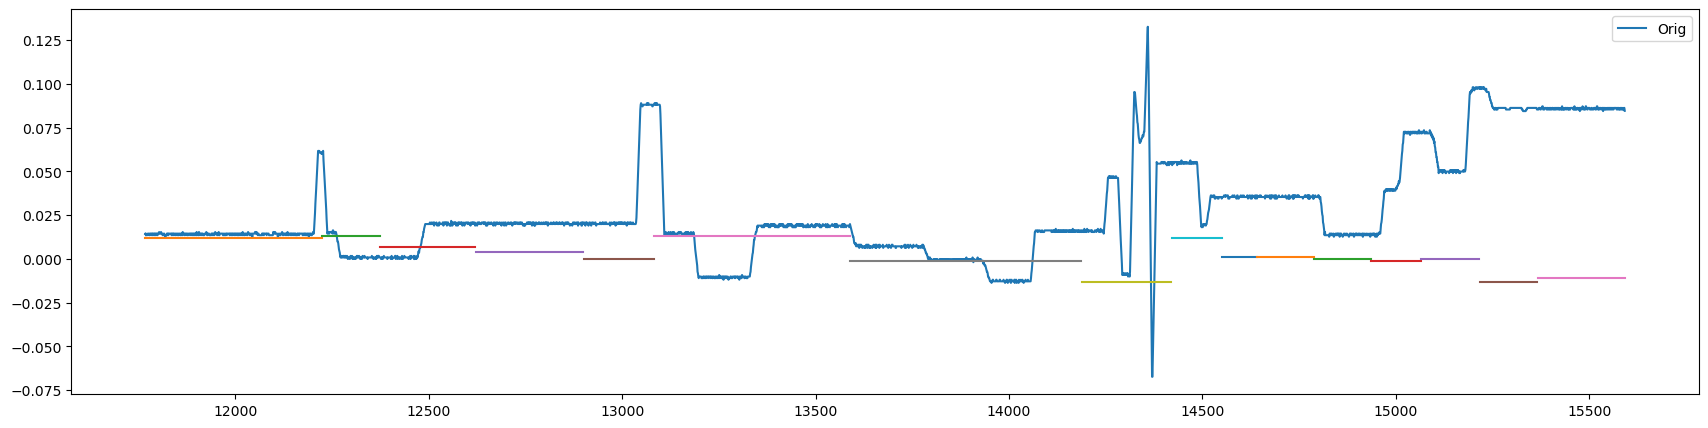

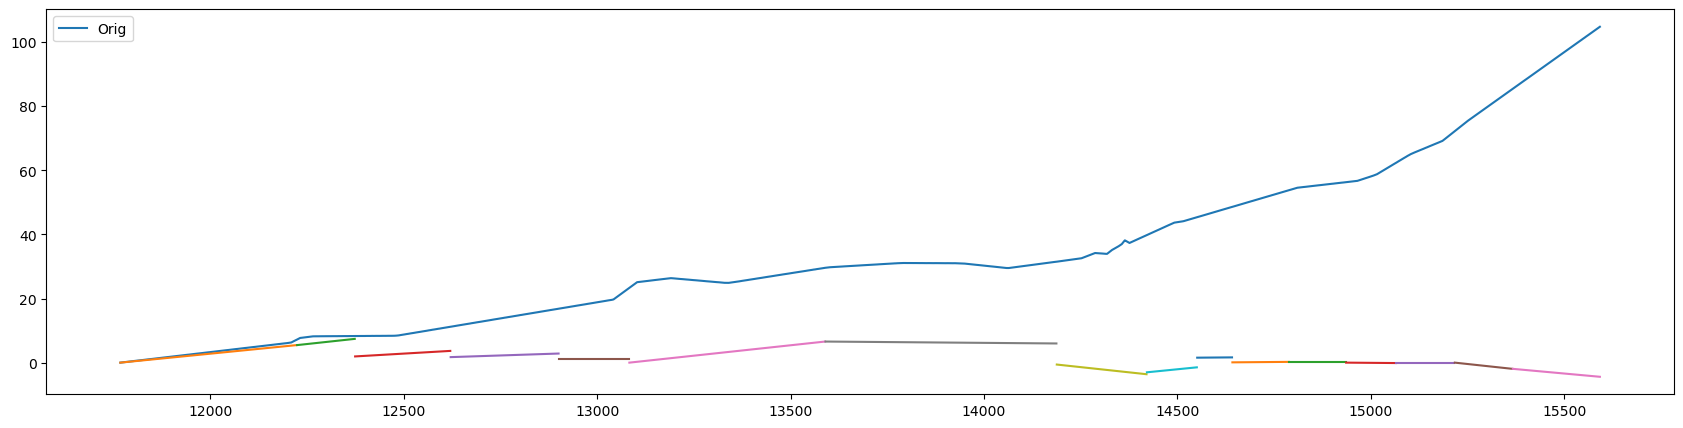

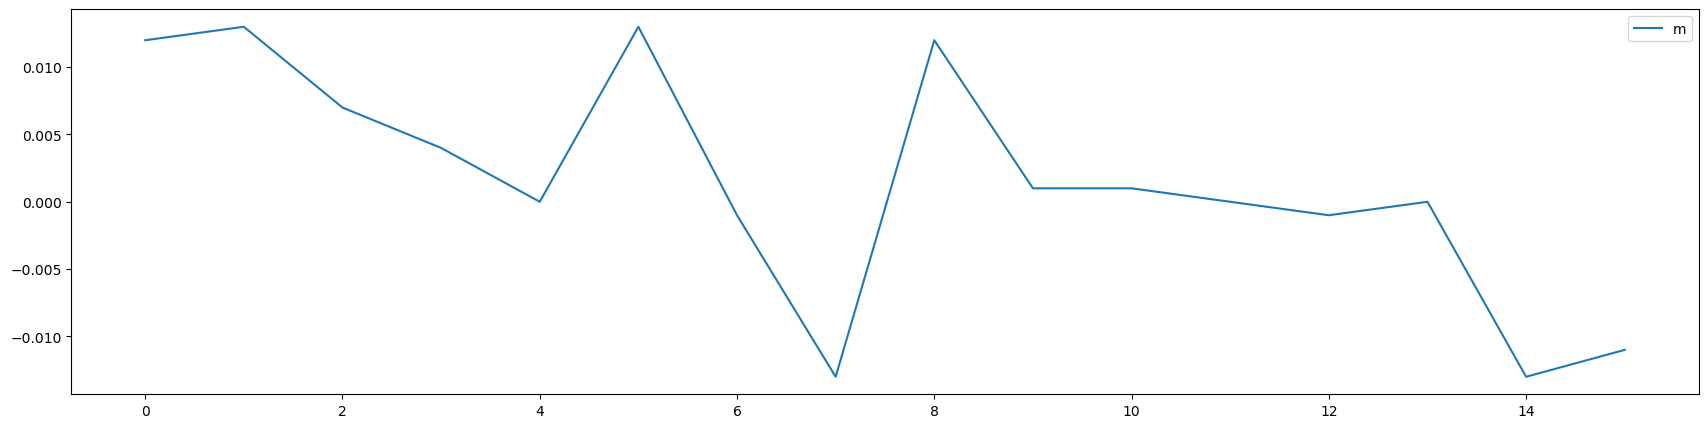

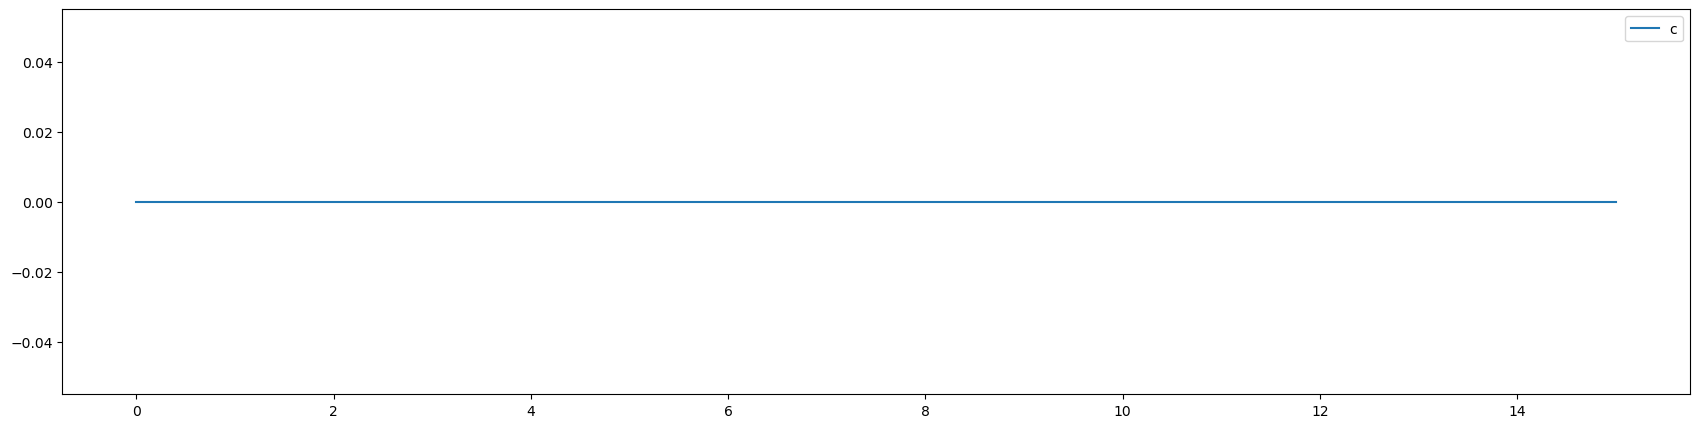

In [260]:
plt.figure(figsize=(21, 5))
gr = np.concat(best_gr_sequence)
plt.plot(evalz['MD'], evalz['GR'], label='Sensed GR (HW)')
plt.plot(evalz['MD'], gr, label='Predicted GR')
gr = np.interp(evalz['TVT'], tw['TVT'], tw['GR'])
plt.plot(evalz['MD'], gr, label='True (TW)')
plt.legend()

plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], evalz['TVT'], label='Truth (HW)')
plt.plot(evalz['MD'], final_tvt, label='Predicted')
plt.legend()
# plt.plot(evalz['MD'], -evalz['TVT'] + 2 * evalz['TVT'].iloc[0])

plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], d(evalz['Z-bl']), label='Orig')
for i, chunk in enumerate(chunks):
    repeat_count = boundaries[i + 1] - boundaries[i]
    plt.plot(chunk['MD'], [best_m_sequence[i]] * repeat_count)
# ms = []
# for i in range(len(boundaries) - 1):
#     ms.extend()
# plt.plot(evalz['MD'], ms, label='Pred')
plt.legend()

plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], evalz['Z-bl'], label='Orig')
o = 0
for i, chunk in enumerate(chunks):
    z = (chunk['MD'] - chunk['MD'].iloc[0]) * best_m_sequence[i] + best_c_sequence[i]
    plt.plot(chunk['MD'], z + o)
    o = z.iloc[-1]
plt.legend()

plt.figure(figsize=(21, 5))
plt.plot(best_m_sequence, label='m')
plt.legend()

plt.figure(figsize=(21, 5))
plt.plot(best_c_sequence, label='c')
plt.legend()

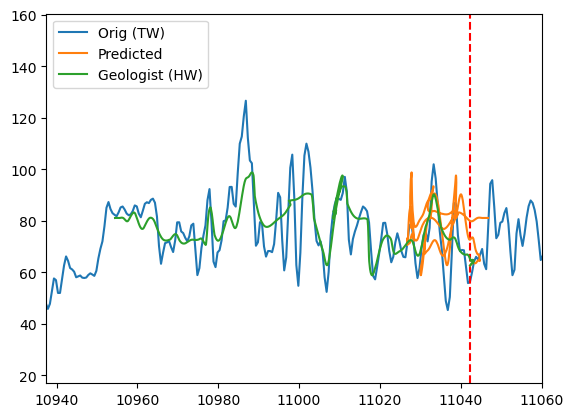

In [213]:
# plt.figure(figsize=(21, 5))
plt.plot(tw['TVT'], tw['GR'], label='Orig (TW)')
tvt0 = evalz['TVT'].iloc[0]
plt.axvline(x=tvt0, color='red', linestyle='--')

plt.plot(final_tvt, evalz['GR'], label='Predicted')
    
plt.plot(evalz['TVT'], evalz['GR'], label='Geologist (HW)')
max_tvt = evalz['TVT'].max()
min_tvt = evalz['TVT'].min()
plt.xlim(min_tvt - 17, max_tvt + 17)
plt.legend()

In [261]:
well

np.str_('fef8af96')

In [173]:
np.sqrt(np.mean(((np.concat(best_gr_sequence) - )**2)))

np.float64(12.054266290013745)

In [174]:
1 - np.corrcoef(np.concat(best_gr_sequence), evalz['GR'])[0, 1]


np.float64(0.31426542691801185)

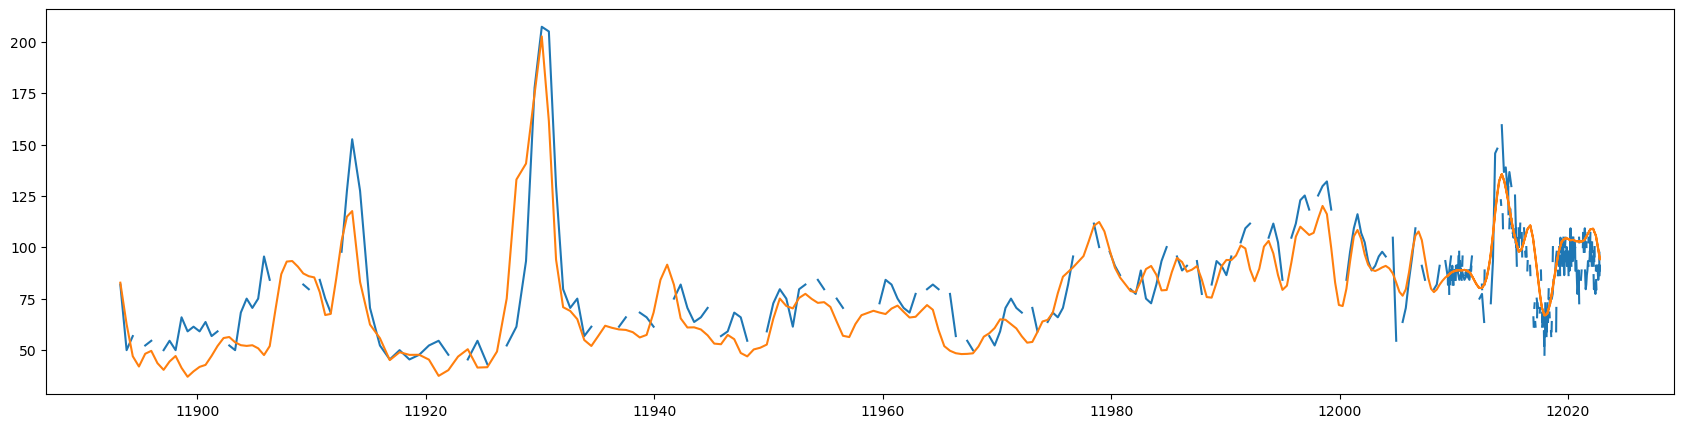

In [155]:
hw = pd.read_csv(os.path.join(train_data, f"{well}__horizontal_well.csv"))
tw = pd.read_csv(os.path.join(train_data, f"{well}__typewell.csv"))
plt.figure(figsize=(21, 5))
mask = hw['TVT_input'].isna()
plt.plot(hw['TVT_input'][~mask][-1000:], hw['GR'][~mask][-1000:])

gr = np.interp(hw['TVT_input'][~mask][-1000:], tw['TVT'], tw['GR'])
plt.plot(hw['TVT_input'][~mask][-1000:], gr)

In [250]:
max_m = 0.15
ms = (np.linspace(-1, 1, 11) ** 2) * max_m
max_c = 9
cs = (np.linspace(-1, 1, 10) ** 3) * max_c
ms

array([0.15 , 0.096, 0.054, 0.024, 0.006, 0.   , 0.006, 0.024, 0.054,
       0.096, 0.15 ])